# M1 – MLP Baseline (feed-forward network on lag / rolling / calendar features)
ICT-4442 Deep Learning Project, Team 10

Uses the team's common preprocessed data (`preprocessing/preprocessing.ipynb`) and its train/validation split (validation = 2015-06-01 to 2015-07-31). Runs on CPU; no GPU needed.

**Run this notebook from the repository root** (the folder that contains `M2_Model.ipynb`).

## 0. Colab only: get the repo and the Kaggle files
Skip this cell when running locally in the cloned repo. In Colab it clones the repo, then asks you to upload Kaggle's `train.csv` and `store.csv` (and `m1_mlp.py` if M1 is not yet pushed to the repo).

In [1]:
import sys, os
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    if not os.path.exists('Deep-Learning'):
        !git clone -q https://github.com/Omkar3599/Deep-Learning.git
    %cd Deep-Learning
    os.makedirs('data/processed', exist_ok=True)
    os.makedirs('M1_MLP', exist_ok=True)
    from google.colab import files
    need = [f for f in ('train.csv', 'store.csv') if not os.path.exists(f'data/{f}')]
    if not os.path.exists('M1_MLP/m1_mlp.py'):
        need.append('m1_mlp.py')
    if need:
        print('Please upload:', ', '.join(need))
        for name in files.upload():
            os.replace(name, f'M1_MLP/{name}' if name.endswith('.py') else f'data/{name}')
print('Working folder:', os.getcwd())

## 1. Create the team's common processed data
Runs Riya's `preprocessing/preprocessing.ipynb` unchanged. It needs `data/train.csv` and writes `data/processed/rossmann_train.csv` and `rossmann_validation.csv`. Skipped if they already exist.

In [2]:
import os
assert os.path.exists('data/train.csv'), 'Put Kaggle train.csv in data/ first'
if os.path.exists('data/processed/rossmann_train.csv') and os.path.exists('data/processed/rossmann_validation.csv'):
    print('Processed files already exist - skipping preprocessing.')
else:
    os.makedirs('data/processed', exist_ok=True)
    !cd preprocessing && jupyter nbconvert --to notebook --execute preprocessing.ipynb --output-dir /tmp --output preprocessing_run.ipynb
!ls -lh data/processed

Processed files already exist - skipping preprocessing.
total 73M
-rw-r--r-- 1 root root  37M Oct 27 05:12 rossmann_processed.csv
-rw-r--r-- 1 root root  34M Oct 27 05:12 rossmann_train.csv
-rw-r--r-- 1 root root 2.5M Oct 27 05:12 rossmann_validation.csv


## 2. Train and evaluate M1
`--store_csv` adds StoreType, Assortment, competition and Promo2 features (same store file M3 uses). Horizon 1 = next-day forecast, as in M2 and M3. Use `HORIZON = 7` for a week-ahead run comparable with M4.

In [3]:
EPOCHS = 25
HORIZON = 1
!python M1_MLP/m1_mlp.py --processed_dir data/processed --store_csv data/store.csv --horizon {HORIZON} --epochs {EPOCHS} --out_dir results/m1_mlp

Loading data ...


Team common split: validation starts 2015-06-01; no separate test set


Building lag/rolling features (horizon = 1 day(s)) ...


Rows (open days, Sales > 0): train 785,727 (2013-01-01 to 2015-05-31) | val 58,611 (2015-06-01 to 2015-07-31)
Stores 1115 | store metadata yes | categorical 9 | numeric 41 (+22 missing-lag flags)


Parameters: 308,279


...

epoch  15 | train MSE(log) 0.0102 | val MAE   547.07 RMSE   792.63 RMSPE  10.36% | 23.8s


epoch  16 | train MSE(log) 0.0099 | val MAE   560.10 RMSE   815.89 RMSPE  10.52% | 24.6s


epoch  17 | train MSE(log) 0.0098 | val MAE   535.44 RMSE   762.52 RMSPE  10.33% | 22.4s
early stopping at epoch 17



Final metrics (original sales scale)
  '<set>'          = open days with Sales > 0 (official Rossmann scoring)
  '<set>_all_rows' = every row incl. closed days (closed predicted as 0)
  val                MAE    537.20 | RMSE    768.01 | RMSPE  10.31% | n=58,611
  val_naive_lag7     MAE   2195.83 | RMSE   2792.50 | RMSPE  40.03% | n=56,831
  val_all_rows       MAE    462.92 | RMSE    712.94 | RMSPE  10.31% | n=68,015



Saved outputs to results/m1_mlp/


## 3. Results
- `val` – open days with Sales > 0 (official Rossmann scoring; main number to report)
- `val_all_rows` – all 68,015 validation rows, closed days predicted as 0 (same rows as M3)
- `val_naive_lag7` – reference forecast: same weekday last week

,MAE,RMSE,RMSPE_%,RMSE_log,n_rows
val,537.20,768.01,10.31,0.10,58611.0
val_naive_lag7,2195.83,2792.50,40.03,0.36,56831.0
val_all_rows,462.92,712.94,10.31,0.09,68015.0


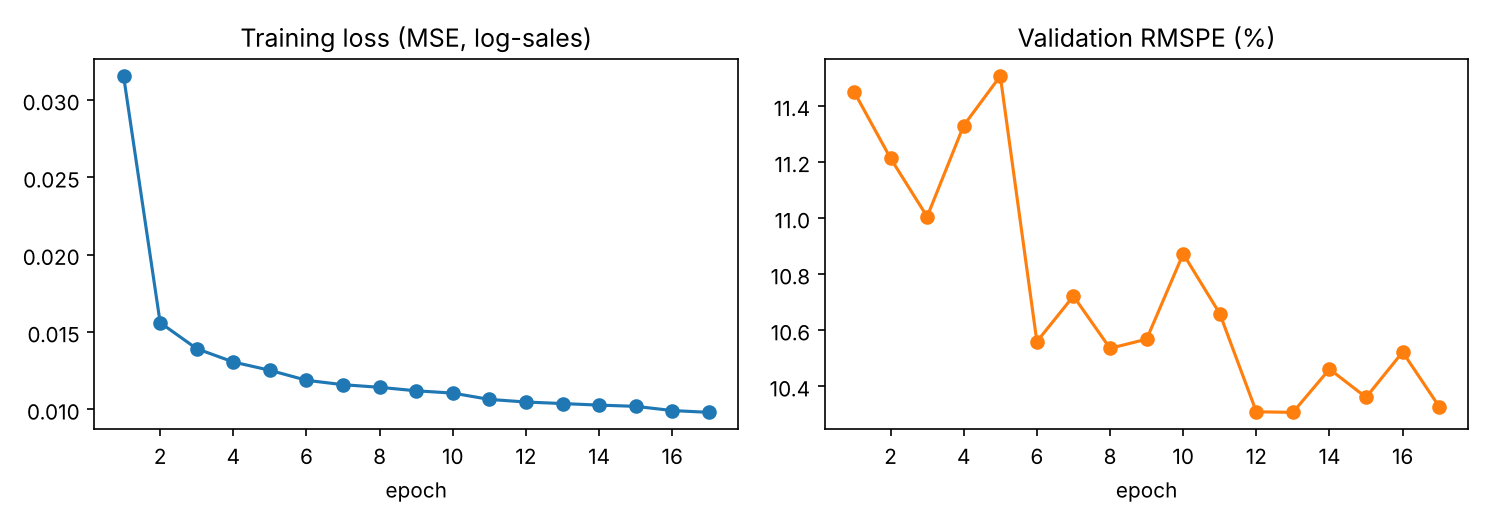

In [4]:
import json, pandas as pd
from IPython.display import Image, display
m = json.load(open('results/m1_mlp/metrics.json'))['results']
display(pd.DataFrame(m).T[['MAE', 'RMSE', 'RMSPE_%', 'RMSE_log', 'n_rows']].round(2))
display(Image('results/m1_mlp/training_curve.png'))

## 4. Optional runs for the final report
Uncomment to run. Week-ahead horizon (comparable with M4) and an embedding ablation (one-hot instead of embeddings).

In [5]:
# !python M1_MLP/m1_mlp.py --processed_dir data/processed --store_csv data/store.csv --horizon 7 --epochs {EPOCHS} --out_dir results/m1_mlp_h7
# !python M1_MLP/m1_mlp.py --processed_dir data/processed --store_csv data/store.csv --no_embeddings --epochs {EPOCHS} --out_dir results/m1_mlp_onehot

## 5. Colab only: download results

In [6]:
if IN_COLAB:
    !zip -q -r m1_results.zip results
    files.download('m1_results.zip')